<a href="https://colab.research.google.com/github/id25s017-blip/AE5510/blob/main/Ayush_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/swarm_criticality_dataset_100_scenarios.csv"

df = pd.read_csv(file_path)

df.head()

,case_id,num_agents,n_obstacles,obstacle_density,mean_obstacle_size,clutter_index,obstacle_clustering,attrition_rate,step,agent_id,...,min_neighbor_dist,weighted_density,angular_coverage,criticality_score,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality,is_critical,was_promoted
0,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,0,...,16.896336,2.925411,0.479167,0.681887,0.745763,0.797297,0.009607,0.062163,True,False
1,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,1,...,6.841428,4.717549,0.437500,0.875107,0.677966,0.756410,0.004853,0.185046,True,False
2,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,2,...,14.777803,1.527958,0.291667,0.673377,0.406780,0.627660,0.001694,0.003368,True,False
3,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,3,...,17.322876,1.250258,0.208333,0.004849,0.525424,0.678161,0.002434,0.037727,False,False
4,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,4,...,5.232741,3.218840,0.458333,0.803172,0.627119,0.728395,0.006355,0.013304,True,False


In [ ]:
print(X_train['attrition_rate'].dtype)
print(X_train['attrition_rate'].unique()[:20])

object
['none' 'heavy' 'medium' 'light']


In [ ]:
df.head(1639166)

,case_id,num_agents,n_obstacles,obstacle_density,mean_obstacle_size,clutter_index,obstacle_clustering,attrition_rate,step,agent_id,...,min_neighbor_dist,weighted_density,angular_coverage,criticality_score,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality,is_critical,was_promoted
0,c001_n60_none,60,2,0.078335,19.789570,0.630676,0.685990,none,0,0,...,16.896336,2.925411,0.479167,6.818867e-01,0.745763,0.797297,0.009607,0.062163,True,False
1,c001_n60_none,60,2,0.078335,19.789570,0.630676,0.685990,none,0,1,...,6.841428,4.717549,0.437500,8.751068e-01,0.677966,0.756410,0.004853,0.185046,True,False
2,c001_n60_none,60,2,0.078335,19.789570,0.630676,0.685990,none,0,2,...,14.777803,1.527958,0.291667,6.733768e-01,0.406780,0.627660,0.001694,0.003368,True,False
3,c001_n60_none,60,2,0.078335,19.789570,0.630676,0.685990,none,0,3,...,17.322876,1.250258,0.208333,4.849149e-03,0.525424,0.678161,0.002434,0.037727,False,False
4,c001_n60_none,60,2,0.078335,19.789570,0.630676,0.685990,none,0,4,...,5.232741,3.218840,0.458333,8.031717e-01,0.627119,0.728395,0.006355,0.013304,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1639161,c100_n24_medium,24,7,0.211031,18.376217,0.833333,0.094408,medium,772,18,...,8.555875,9.482131,0.291667,4.531575e-02,1.000000,1.000000,0.000000,0.210476,False,False
1639162,c100_n24_medium,24,7,0.211031,18.376217,0.833333,0.094408,medium,772,19,...,7.029975,9.335214,0.187500,5.247888e-02,1.000000,1.000000,0.000000,0.214841,False,False
1639163,c100_n24_medium,24,7,0.211031,18.376217,0.833333,0.094408,medium,772,20,...,29.802764,0.279086,0.125000,6.694056e-15,1.000000,1.000000,0.000000,0.004307,False,False
1639164,c100_n24_medium,24,7,0.211031,18.376217,0.833333,0.094408,medium,772,21,...,4.134056,11.357656,0.250000,9.327945e-01,1.000000,1.000000,0.000000,0.257731,True,False


In [ ]:
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score

# 1. Load the data. This reads the CSV into a table (a "DataFrame") you can work with in code.
file_path = "/content/drive/MyDrive/Aerial Swarm Dataset/swarm_criticality_dataset_100_scenarios.csv"

df = pd.read_csv(file_path)

# 1b. FIX: "attrition_rate" is a categorical severity label ('none'/'light'/'medium'/'heavy'),
#     not a number — LightGBM needs numeric input, so map it to an ordered integer scale.
#     Doing this on the full df (not X_train/X_test separately) is fine here because it's a
#     fixed, hand-defined mapping — nothing is being learned from the data, so there's no
#     leakage risk from doing it before the train/test split.
attrition_order = {"none": 0, "light": 1, "medium": 2, "heavy": 3}
df["attrition_rate"] = df["attrition_rate"].map(attrition_order)

# sanity check — catches typos/unexpected category values before they silently become NaN
assert df["attrition_rate"].isna().sum() == 0, "Unexpected attrition_rate value found — check df['attrition_rate'].unique()"

# 2. Decide which columns are INPUTS (features the model is allowed to look at)
#    and which column is the ANSWER it's trying to predict.
#    Do not include case_id, criticality_score, or is_critical as inputs — those
#    would be "cheating" (is_critical/criticality_score ARE the answer; case_id just
#    identifies the scenario and carries no real predictive signal of its own).
feature_columns = [
    "num_agents", "n_obstacles", "obstacle_density", "mean_obstacle_size",
    "clutter_index", "obstacle_clustering", "attrition_rate",
    "min_neighbor_dist", "weighted_density", "angular_coverage",
    "degree_centrality", "closeness_centrality", "betweenness_centrality", "eigenvector_centrality",
    # add the kinematics columns here once you have the full column list —
    # position/velocity/heading/acceleration fields
]
X = df[feature_columns]      # X = the inputs, by ML convention
y = df["is_critical"]        # y = the answer column, by ML convention

# 3. Split the data into a TRAINING set (what the model learns from) and a TEST set
#    (rows it never sees during training, used afterward to check if it actually
#    learned something general, rather than just memorizing).
#    stratify=y keeps the same proportion of critical/non-critical rows in both splits.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Create and train the model. This is the actual "learning" step — internally,
#    it repeats the hand-worked process from Part 1 hundreds of times.
model = lgb.LGBMClassifier(
    n_estimators=300,      # how many small trees to build (rounds of boosting)
    learning_rate=0.05,    # how much to trust each individual tree (see Part 1, Step 4)
    max_depth=5,           # how many yes/no questions deep each tree can go
    random_state=42,
)
model.fit(X_train, y_train)

# 5. Use the trained model to predict on the test set (rows it has never seen).
y_pred = model.predict(X_test)                       # yes/no predictions
y_pred_proba = model.predict_proba(X_test)[:, 1]      # confidence score, 0 to 1

# 6. Score it, using the metrics from the Approach slide.
print("Accuracy:  ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall:    ", recall_score(y_test, y_pred))
print("F1:        ", f1_score(y_test, y_pred))
print("AUC-PR:    ", average_precision_score(y_test, y_pred_proba))

# 7. Which features mattered most? This is the "feature importance" from the slide —
#    a ranked list of which inputs the model relied on most.
importances = pd.Series(model.feature_importances_, index=feature_columns)
print(importances.sort_values(ascending=False))

[LightGBM] [Info] Number of positive: 510596, number of negative: 800736
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.382628 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1935
[LightGBM] [Info] Number of data points in the train set: 1311332, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.389372 -> initscore=-0.449953
[LightGBM] [Info] Start training from score -0.449953
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive

In [ ]:
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score

# 1. Load the data. This reads the CSV into a table (a "DataFrame") you can work with in code.
file_path = "/content/drive/MyDrive/Aerial Swarm Dataset/swarm_criticality_dataset_100_scenarios.csv"

df = pd.read_csv(file_path)

# 1b. "attrition_rate" is a categorical severity label ('none'/'light'/'medium'/'heavy'),
#     not a number — LightGBM needs numeric input, so map it to an ordered integer scale.
attrition_order = {"none": 0, "light": 1, "medium": 2, "heavy": 3}
df["attrition_rate"] = df["attrition_rate"].map(attrition_order)
assert df["attrition_rate"].isna().sum() == 0, "Unexpected attrition_rate value — check df['attrition_rate'].unique()"

# 2. Decide which columns are INPUTS (features the model is allowed to look at)
#    and which column is the ANSWER it's trying to predict.
#    Do not include case_id, criticality_score, or is_critical as inputs — those
#    would be "cheating" (is_critical/criticality_score ARE the answer; case_id just
#    identifies the scenario and carries no real predictive signal of its own).
feature_columns = [
    "num_agents", "n_obstacles", "obstacle_density", "mean_obstacle_size",
    "clutter_index", "obstacle_clustering", "attrition_rate",
    "min_neighbor_dist", "weighted_density", "angular_coverage",
    "degree_centrality", "closeness_centrality", "betweenness_centrality", "eigenvector_centrality",
    # add the kinematics columns here once you have the full column list —
    # position/velocity/heading/acceleration fields
]
X = df[feature_columns]      # X = the inputs, by ML convention
y = df["is_critical"]        # y = the answer column, by ML convention

# 3. Split the data into a TRAINING set (what the model learns from) and a TEST set
#    (rows it never sees during training, used afterward to check if it actually
#    learned something general, rather than just memorizing).
#    stratify=y keeps the same proportion of critical/non-critical rows in both splits.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Create and train the model. This is the actual "learning" step — internally,
#    it repeats the hand-worked process from Part 1 hundreds of times.
model = lgb.LGBMClassifier(
    n_estimators=300,      # how many small trees to build (rounds of boosting)
    learning_rate=0.05,    # how much to trust each individual tree (see Part 1, Step 4)
    max_depth=5,           # how many yes/no questions deep each tree can go
    random_state=42,
    verbose=-1,            # suppress LightGBM's internal Info/Warning logging — cosmetic only
)
model.fit(X_train, y_train)

# 5. Use the trained model to predict on the test set (rows it has never seen).
y_pred = model.predict(X_test)                       # yes/no predictions at the default 0.5 threshold
y_pred_proba = model.predict_proba(X_test)[:, 1]      # confidence score, 0 to 1

# 6. Score it at the default threshold (0.5), using the metrics from the Approach slide.
print("=== Default threshold (0.5) ===")
print("Accuracy:  ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall:    ", recall_score(y_test, y_pred))
print("F1:        ", f1_score(y_test, y_pred))
print("AUC-PR:    ", average_precision_score(y_test, y_pred_proba))

# 6b. Threshold tuning. AUC-PR (0.93) was high but recall (0.79) trailed precision (0.86) at
#     the default 0.5 cutoff — meaning ~1 in 5 truly critical nodes were being missed. In a
#     safety-critical setting, missing a critical node (false negative) is usually costlier
#     than a false alarm (false positive), so it's worth checking whether a lower threshold
#     trades a bit of precision for meaningfully better recall.
print("\n=== Threshold sweep ===")
for threshold in [0.5, 0.45, 0.40, 0.35, 0.30, 0.25]:
    y_pred_t = (y_pred_proba >= threshold).astype(int)
    print(
        f"threshold={threshold:.2f} | "
        f"Precision={precision_score(y_test, y_pred_t):.3f}  "
        f"Recall={recall_score(y_test, y_pred_t):.3f}  "
        f"F1={f1_score(y_test, y_pred_t):.3f}"
    )

# Once you've picked the threshold that best balances precision/recall for your use case,
# set it here and regenerate the final predictions/metrics for your report:
chosen_threshold = 0.35  # <-- update based on the sweep above
y_pred_final = (y_pred_proba >= chosen_threshold).astype(int)
print(f"\n=== Final chosen threshold ({chosen_threshold}) ===")
print("Accuracy:  ", accuracy_score(y_test, y_pred_final))
print("Precision: ", precision_score(y_test, y_pred_final))
print("Recall:    ", recall_score(y_test, y_pred_final))
print("F1:        ", f1_score(y_test, y_pred_final))

# 7. Which features mattered most? This is the "feature importance" from the slide —
#    a ranked list of which inputs the model relied on most.
importances = pd.Series(model.feature_importances_, index=feature_columns)
print("\n=== Feature importances ===")
print(importances.sort_values(ascending=False))

=== Default threshold (0.5) ===
Accuracy:   0.8693729143407944
Precision:  0.862490705366529
Recall:     0.7905584845944739
F1:         0.8249595343590079
AUC-PR:     0.927530595027848

=== Threshold sweep ===
threshold=0.50 | Precision=0.862  Recall=0.791  F1=0.825
threshold=0.45 | Precision=0.837  Recall=0.824  F1=0.831
threshold=0.40 | Precision=0.809  Recall=0.856  F1=0.832
threshold=0.35 | Precision=0.779  Recall=0.885  F1=0.829
threshold=0.30 | Precision=0.748  Recall=0.911  F1=0.822
threshold=0.25 | Precision=0.716  Recall=0.935  F1=0.811

=== Final chosen threshold (0.35) ===
Accuracy:   0.8575803607923522
Precision:  0.7792094027410866
Recall:     0.8849971405964794
F1:         0.8287409950555336

=== Feature importances ===
eigenvector_centrality    1589
weighted_density          1147
min_neighbor_dist         1077
betweenness_centrality     785
angular_coverage           776
degree_centrality          677
obstacle_clustering        631
mean_obstacle_size         550
num_agen

In [ ]:
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score

In [ ]:
file_path = "/content/drive/MyDrive/swarm_criticality_dataset_100_scenarios.csv"
df = pd.read_csv(file_path)

In [ ]:
print(df.shape)          # (number of rows, number of columns)
print(df.columns.tolist())  # confirm all expected columns are present
df.head()                # eyeball the first 5 rows

(1639166, 37)
['case_id', 'num_agents', 'n_obstacles', 'obstacle_density', 'mean_obstacle_size', 'clutter_index', 'obstacle_clustering', 'attrition_rate', 'step', 'agent_id', 'rel_x', 'rel_y', 'rel_z', 'dist_to_centroid', 'rank_dist_to_centroid', 'dist_to_target', 'rank_dist_to_target', 'vx', 'vy', 'vz', 'speed', 'heading', 'flight_path_angle', 'accel', 'heading_rate', 'num_neighbors', 'mean_neighbor_dist', 'min_neighbor_dist', 'weighted_density', 'angular_coverage', 'criticality_score', 'degree_centrality', 'closeness_centrality', 'betweenness_centrality', 'eigenvector_centrality', 'is_critical', 'was_promoted']


,case_id,num_agents,n_obstacles,obstacle_density,mean_obstacle_size,clutter_index,obstacle_clustering,attrition_rate,step,agent_id,...,min_neighbor_dist,weighted_density,angular_coverage,criticality_score,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality,is_critical,was_promoted
0,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,0,...,16.896336,2.925411,0.479167,0.681887,0.745763,0.797297,0.009607,0.062163,True,False
1,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,1,...,6.841428,4.717549,0.437500,0.875107,0.677966,0.756410,0.004853,0.185046,True,False
2,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,2,...,14.777803,1.527958,0.291667,0.673377,0.406780,0.627660,0.001694,0.003368,True,False
3,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,3,...,17.322876,1.250258,0.208333,0.004849,0.525424,0.678161,0.002434,0.037727,False,False
4,c001_n60_none,60,2,0.078335,19.78957,0.630676,0.68599,none,0,4,...,5.232741,3.218840,0.458333,0.803172,0.627119,0.728395,0.006355,0.013304,True,False


In [ ]:
attrition_order = {"none": 0, "light": 1, "medium": 2, "heavy": 3}
df["attrition_rate"] = df["attrition_rate"].map(attrition_order)
assert df["attrition_rate"].isna().sum() == 0, "Unexpected attrition_rate value — check df['attrition_rate'].unique()"

In [ ]:
feature_columns = [
    "num_agents", "n_obstacles", "obstacle_density", "mean_obstacle_size",
    "clutter_index", "obstacle_clustering", "attrition_rate",
    "min_neighbor_dist", "weighted_density", "angular_coverage",
    "degree_centrality", "closeness_centrality", "betweenness_centrality", "eigenvector_centrality",
]
X = df[feature_columns]
y = df["is_critical"]
criticality_score = df["criticality_score"]

In [ ]:
X_train, X_test, y_train, y_test, score_train, score_test = train_test_split(
    X, y, criticality_score, test_size=0.5, random_state=42, stratify=y
)
print("Training rows:", len(X_train), " | Test rows:", len(X_test))

Training rows: 819583  | Test rows: 819583


In [ ]:
model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    verbose=-1,
)
model.fit(X_train, y_train)

LGBMClassifier(learning_rate=0.05, max_depth=5, n_estimators=300,
               random_state=42, verbose=-1)

In [ ]:
y_pred = model.predict(X_test)                       # hard yes/no calls
y_pred_proba = model.predict_proba(X_test)[:, 1]      # confidence score, 0 to 1

In [ ]:
print("Accuracy:  ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall:    ", recall_score(y_test, y_pred))
print("F1:        ", f1_score(y_test, y_pred))
print("AUC-PR:    ", average_precision_score(y_test, y_pred_proba))

Accuracy:   0.868922366618146
Precision:  0.8632655512655513
Recall:     0.7882063912860913
F1:         0.8240302573149417
AUC-PR:     0.9266372702655971


In [ ]:
k = 819583
top_k_idx = y_pred_proba.argsort()[::-1][:k]
print(f"Top-{k} hit rate:", y_test.iloc[top_k_idx].mean())
print(f"Top-{k} mean criticality_score:", score_test.iloc[top_k_idx].mean(), " | test-set average:", score_test.mean())

Top-819583 hit rate: 0.38937118022213735
Top-819583 mean criticality_score: 0.3135045881419575  | test-set average: 0.31350458814195753


In [ ]:
importances = pd.Series(model.feature_importances_, index=feature_columns)
print(importances.sort_values(ascending=False))

eigenvector_centrality    1583
weighted_density          1222
min_neighbor_dist         1061
angular_coverage           809
betweenness_centrality     752
degree_centrality          637
obstacle_clustering        615
mean_obstacle_size         551
num_agents                 471
obstacle_density           332
closeness_centrality       278
attrition_rate             220
n_obstacles                219
clutter_index              197
dtype: int32


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, precision_recall_curve, precision_score, recall_score, f1_score

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
})
ACCENT = "#4C72B0"    # primary blue — single-series charts
ACCENT2 = "#DD8452"   # orange — second series in 2-series comparisons

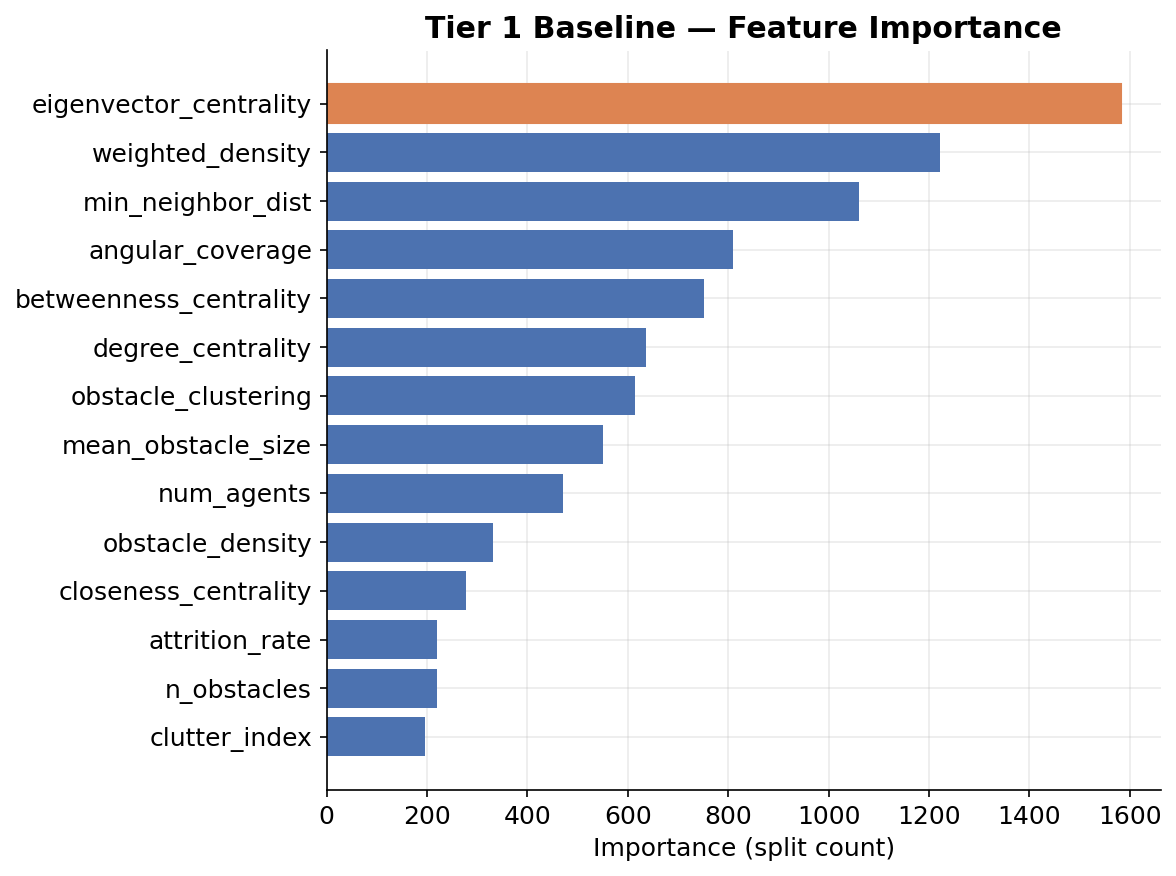

In [ ]:
imp_sorted = importances.sort_values(ascending=True)  # ascending so biggest bar is on top when plotted horizontally
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(imp_sorted.index, imp_sorted.values, color=ACCENT)
bars[-1].set_color(ACCENT2)  # highlight the top feature
ax.set_xlabel("Importance (split count)")
ax.set_title("Tier 1 Baseline — Feature Importance", fontweight="bold")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

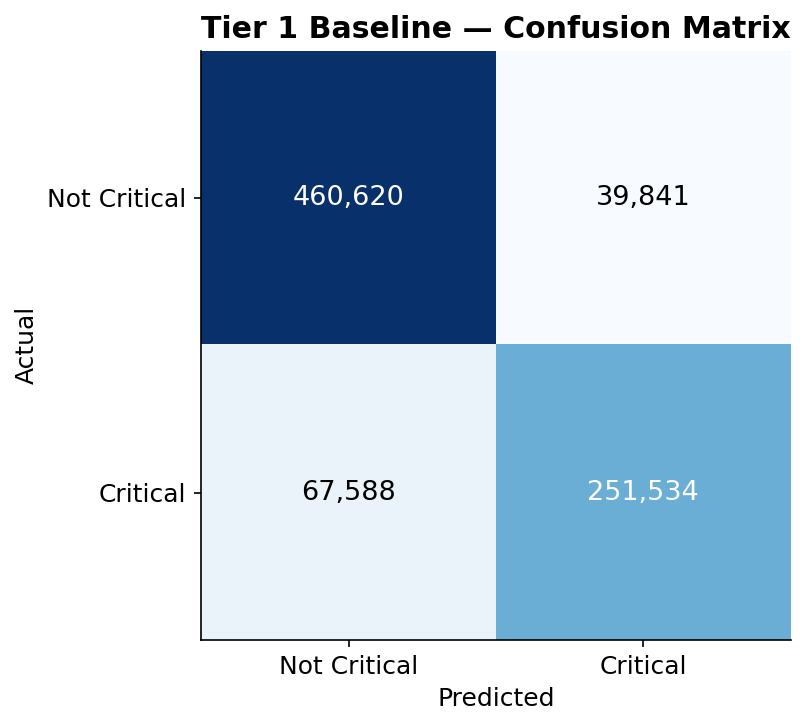

In [ ]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Not Critical", "Critical"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Not Critical", "Critical"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Tier 1 Baseline — Confusion Matrix", fontweight="bold")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
ax.grid(False)
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

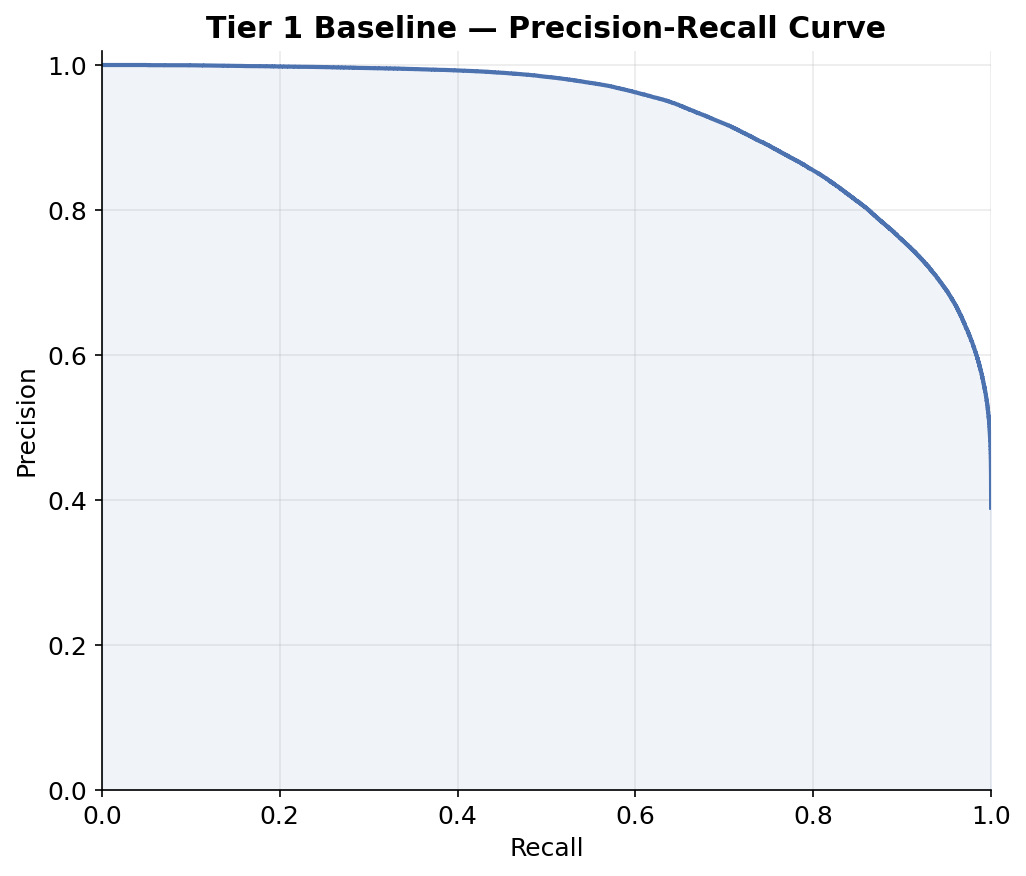

In [ ]:
precisions, recalls, _ = precision_recall_curve(y_test, y_pred_proba)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recalls, precisions, color=ACCENT, linewidth=2)
ax.fill_between(recalls, precisions, alpha=0.08, color=ACCENT)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Tier 1 Baseline — Precision-Recall Curve", fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig("precision_recall_curve.png")
plt.show()

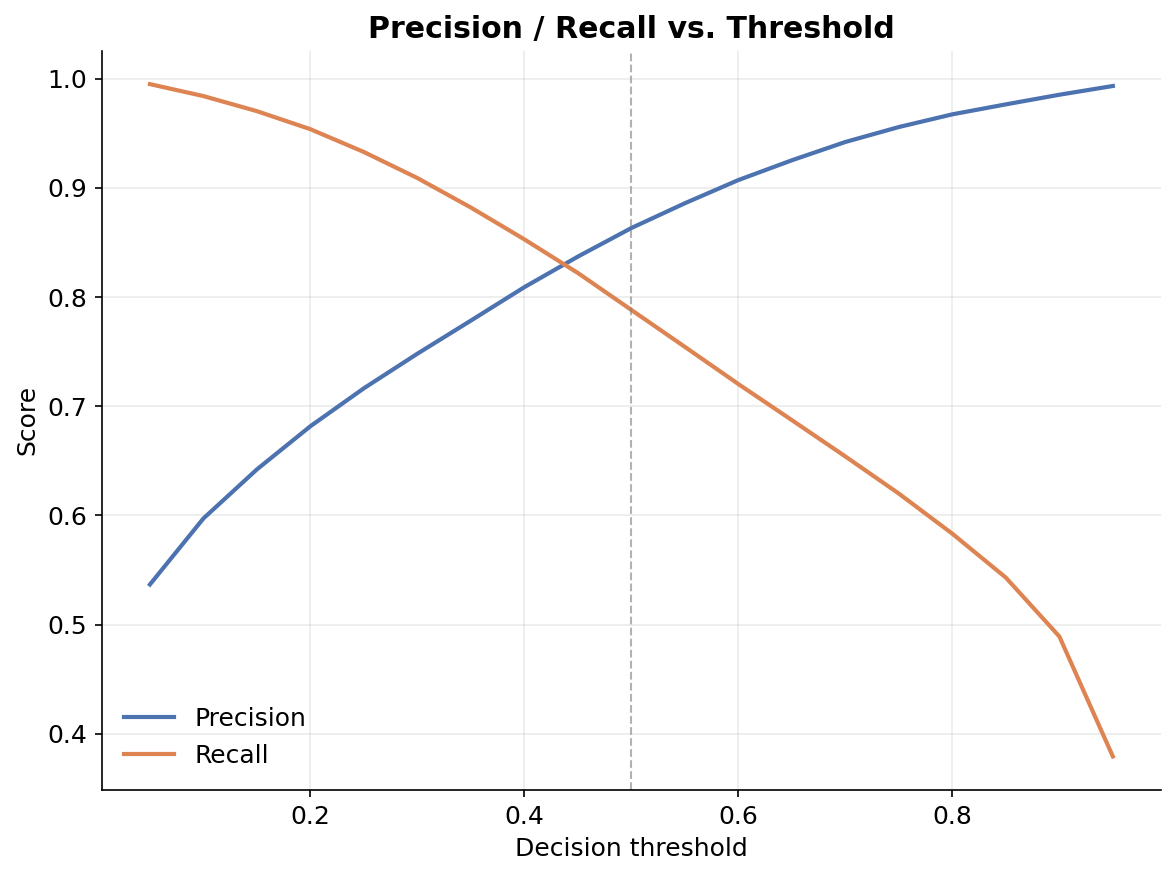

In [ ]:
thresholds = np.arange(0.05, 0.96, 0.05)
prec_vals, rec_vals = [], []
for t in thresholds:
    pred_t = (y_pred_proba >= t).astype(int)
    prec_vals.append(precision_score(y_test, pred_t))
    rec_vals.append(recall_score(y_test, pred_t))

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(thresholds, prec_vals, color=ACCENT, linewidth=2, label="Precision")
ax.plot(thresholds, rec_vals, color=ACCENT2, linewidth=2, label="Recall")
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1, alpha=0.6)
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score")
ax.set_title("Precision / Recall vs. Threshold", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("threshold_sweep.png")
plt.show()

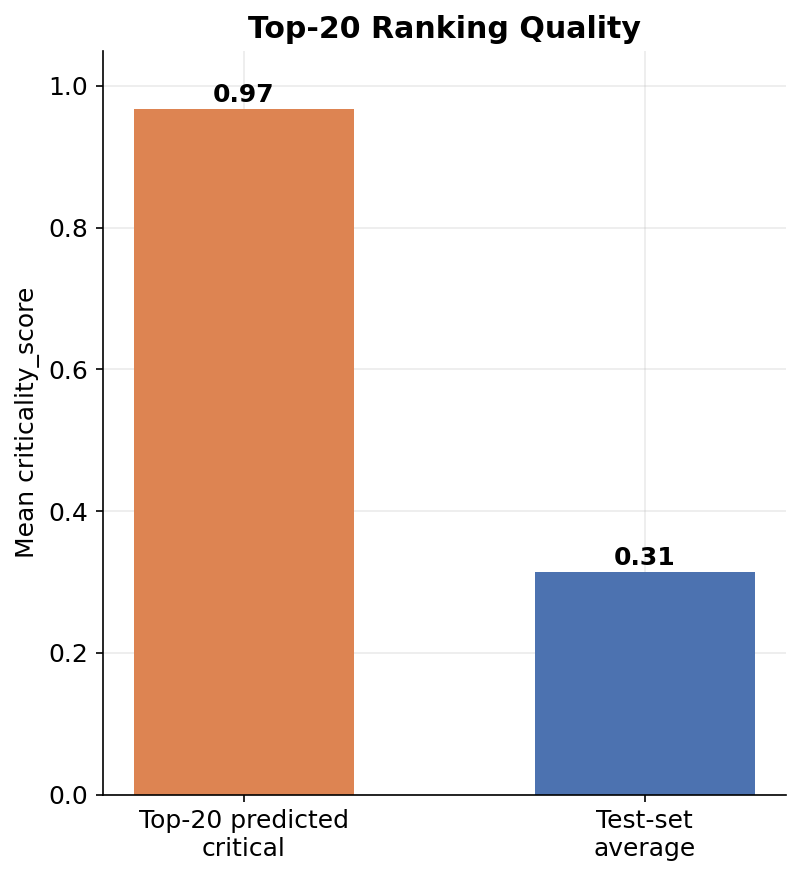

In [ ]:
k = 20
top_k_idx = y_pred_proba.argsort()[::-1][:k]
top_k_mean = score_test.iloc[top_k_idx].mean()
overall_mean = score_test.mean()

fig, ax = plt.subplots(figsize=(5.5, 6))
bars = ax.bar(["Top-20 predicted\ncritical", "Test-set\naverage"],
               [top_k_mean, overall_mean], color=[ACCENT2, ACCENT], width=0.55)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f"{bar.get_height():.2f}", ha="center", fontweight="bold")
ax.set_ylabel("Mean criticality_score")
ax.set_title(f"Top-{k} Ranking Quality", fontweight="bold")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig("topk_comparison.png")
plt.show()

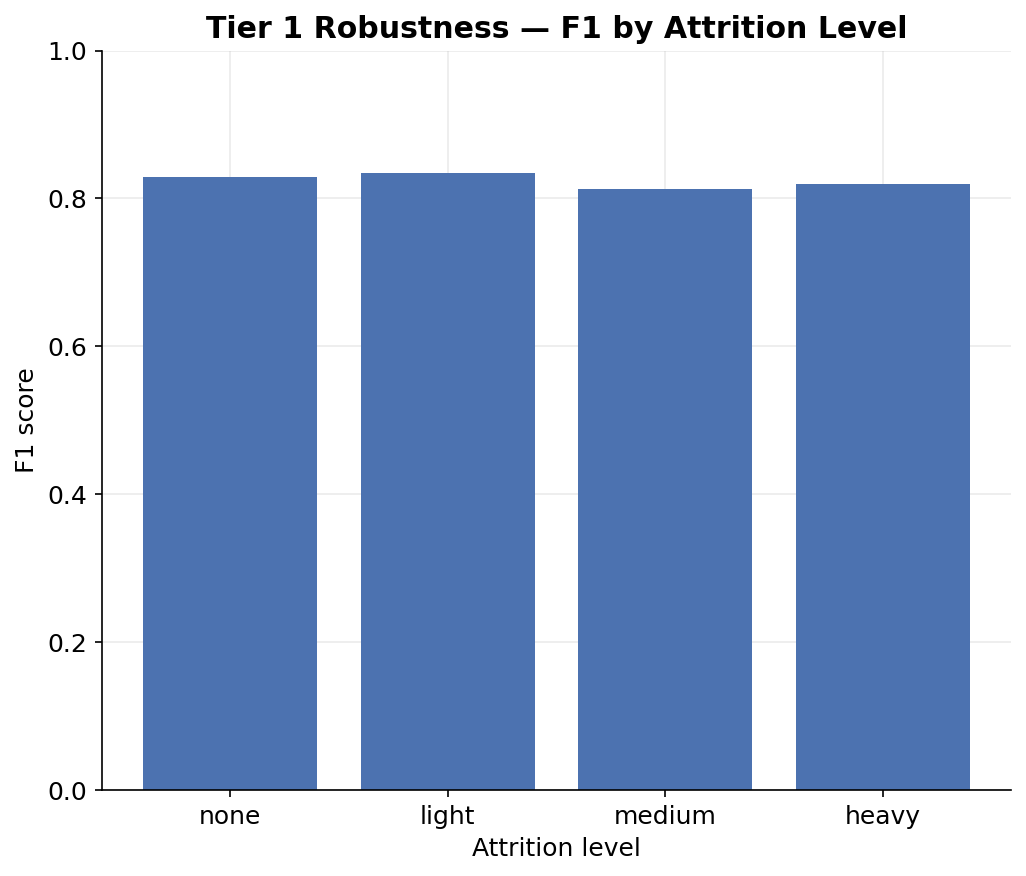

In [ ]:
attrition_labels = {0: "none", 1: "light", 2: "medium", 3: "heavy"}
test_attrition = df.loc[X_test.index, "attrition_rate"]

f1_by_group = []
for level in sorted(attrition_labels):
    mask = (test_attrition == level).values
    if mask.sum() > 0:
        f1_by_group.append(f1_score(y_test[mask], y_pred[mask]))
    else:
        f1_by_group.append(np.nan)

fig, ax = plt.subplots(figsize=(7, 6))
ax.bar([attrition_labels[l] for l in sorted(attrition_labels)], f1_by_group, color=ACCENT)
ax.set_ylabel("F1 score")
ax.set_xlabel("Attrition level")
ax.set_title("Tier 1 Robustness — F1 by Attrition Level", fontweight="bold")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("f1_by_attrition.png")
plt.show()